# 01 · Target definition

**Plan:** cost function → payment timing → completing censored cohorts → target candidates → NPV sensitivity → time-based splits → save the modelling dataset.

## 0. Setup

In [1]:
import os, sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/Court-Recovery-Model")
else:
    PROJECT_DIR = Path(os.environ.get("PROJECT_DIR", "..")).resolve()

PROC_DIR = PROJECT_DIR / "data" / "processed"
FIG_DIR = PROJECT_DIR / "reports" / "figures"
CONFIG_DIR = PROJECT_DIR / "config"
for p in (PROC_DIR, FIG_DIR, CONFIG_DIR):
    p.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

FIXED_COST = 500
VAR_COST_RATE = 0.10
FEE_BASIS = "client"
HORIZON = 24
ANNUAL_DISCOUNT = 0.12

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

PAY_COLS = [f"M{i:02d}_PAID" for i in range(1, HORIZON + 1)]

Mounted at /content/drive


In [2]:
pq = PROC_DIR / "client_period_unsecured.parquet"
df = pd.read_parquet(pq) if pq.exists() else pd.read_csv(PROC_DIR / "client_period_unsecured.csv")
df["PERIOD_DT"] = pd.to_datetime(df.PERIOD, format="%Y/%m")
df = df.sort_values(["PERIOD_DT", "CLIENT_KEY"]).reset_index(drop=True)

FEATURES = [c for c in df.columns if c.startswith("feature_")] + ["has_secured_loans", "n_loans", "outst"]
print(f"Rows: {len(df):,} | fully observed: {df.fully_observed.sum():,} | features available: {len(FEATURES)}")
print(f"Cohorts: {df.PERIOD.min()} … {df.PERIOD.max()} | months observed: {df.months_obs.min()}–{df.months_obs.max()}")

Rows: 27,029 | fully observed: 11,560 | features available: 52
Cohorts: 2023/01 … 2026/02 | months observed: 6–24


## 1. Cost of a court case


In [3]:
def court_cost(outst, n_loans, basis=FEE_BASIS):
    fixed = FIXED_COST * (n_loans if basis == "loan" else 1)
    return fixed + VAR_COST_RATE * outst

df["court_cost"] = court_cost(df.outst, df.n_loans)
display(df.court_cost.describe(percentiles=[.1, .5, .9]).to_frame("court_cost_GEL").T)
print(f"Fixed fee as share of total cost (median client): "
      f"{(FIXED_COST / df.court_cost).median():.0%}")

,count,mean,std,min,10%,50%,90%,max
court_cost_GEL,"27,029.000","1,202.613",859.163,502.010,585.167,946.423,"2,081.080","18,554.279"


Fixed fee as share of total cost (median client): 53%


## 2. When does recovery start?


In [4]:
full = df[df.fully_observed].copy()
cum_full = full[PAY_COLS].cumsum(axis=1)

payers = full.paid_total > 0
first_pay = (full.loc[payers, PAY_COLS].values > 0).argmax(axis=1) + 1
print(f"Clients who pay anything in 24m: {payers.mean():.1%}")
print(f"…of whom the first payment is in month 1: {(first_pay == 1).mean():.1%}, "
      f"by month 3: {(first_pay <= 3).mean():.1%}")

late = []
for k in [1, 3, 6, 12]:
    zero_k = cum_full[PAY_COLS[k - 1]] == 0
    later = zero_k & payers
    late.append({"month_k": k,
                 "share_zero_by_k": zero_k.mean(),
                 "of_those_pay_later": later.sum() / zero_k.sum(),
                 "share_of_24m_money_from_late_starters": full.paid_total[later].sum() / full.paid_total.sum()})
display(pd.DataFrame(late).set_index("month_k"))

Clients who pay anything in 24m: 53.3%
…of whom the first payment is in month 1: 99.7%, by month 3: 99.9%


,share_zero_by_k,of_those_pay_later,share_of_24m_money_from_late_starters
month_k,,,
1,0.468,0.004,0.000
3,0.467,0.002,0.000
6,0.467,0.001,0.000
12,0.467,0.000,0.000


## 3. Completing censored cohorts (development factors)

In [5]:
dev = pd.Series({k: full.paid_total.sum() / cum_full[PAY_COLS[k - 1]].sum() for k in range(1, HORIZON + 1)},
                name="factor_to_24m")
dev.index.name = "months_observed"
display(dev.loc[[3, 6, 9, 12, 18, 23, 24]].to_frame().T)

actual = full.paid_total
rows = []
for k in range(3, HORIZON):
    proj = cum_full[PAY_COLS[k - 1]] * dev[k]
    rel_err = (proj[payers] - actual[payers]).abs() / actual[payers]
    rows.append({"k": k,
                 "total_projected / actual": proj.sum() / actual.sum(),
                 "spearman_client_level": proj.corr(actual, method="spearman"),
                 "profitable_label_agreement": ((proj - full.court_cost > 0) == (full.net_value > 0)).mean(),
                 "median_abs_rel_error_payers": rel_err.median()})
bt = pd.DataFrame(rows).set_index("k")
display(bt.loc[[3, 6, 9, 12, 18]])

months_observed,3,6,9,12,18,23,24
factor_to_24m,4.600,2.436,1.743,1.405,1.097,1.007,1.000


,total_projected / actual,spearman_client_level,profitable_label_agreement,median_abs_rel_error_payers
k,,,,
3,1.000,0.998,0.973,0.207
6,1.000,0.999,0.984,0.134
9,1.000,1.000,0.989,0.093
12,1.000,1.000,0.992,0.068
18,1.000,1.000,0.996,0.035


In [6]:
k = 6
proj6 = cum_full[PAY_COLS[k - 1]] * dev[k]
seg = full.assign(proj=proj6,
                  balance_quintile=pd.qcut(full.outst, 5, labels=[f"Q{i}" for i in range(1, 6)]),
                  cohort_half=np.where(full.PERIOD < "2023/11", "2023-01…2023-10", "2023-11…2024-08"))
for col in ["balance_quintile", "has_secured_loans", "cohort_half"]:
    r = seg.groupby(col, observed=True).apply(lambda g: g.proj.sum() / g.paid_total.sum()).rename("projected/actual")
    display(r.to_frame().T)

balance_quintile,Q1,Q2,Q3,Q4,Q5
projected/actual,1.000,1.004,0.996,1.007,0.998


has_secured_loans,0,1
projected/actual,1.005,0.980


cohort_half,2023-01…2023-10,2023-11…2024-08
projected/actual,1.002,0.998


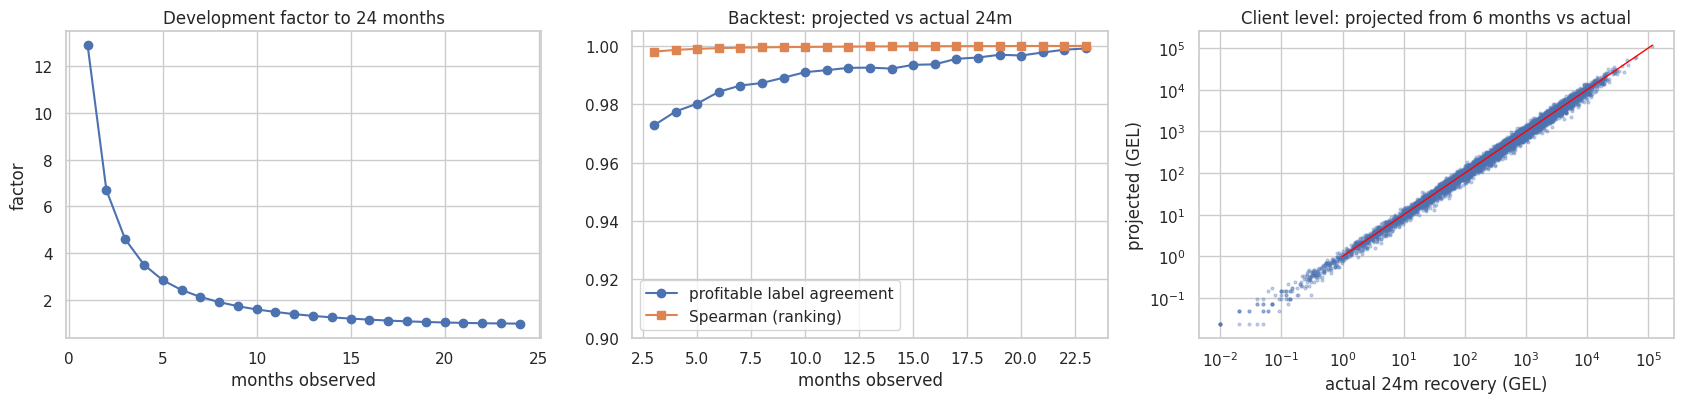

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].plot(dev.index, dev.values, marker="o")
axes[0].set(title="Development factor to 24 months", xlabel="months observed", ylabel="factor")
axes[1].plot(bt.index, bt["profitable_label_agreement"], marker="o", label="profitable label agreement")
axes[1].plot(bt.index, bt["spearman_client_level"], marker="s", label="Spearman (ranking)")
axes[1].set(title="Backtest: projected vs actual 24m", xlabel="months observed", ylim=(0.9, 1.005))
axes[1].legend()
m = payers.values
axes[2].scatter(actual[m], proj6[m], s=4, alpha=0.3)
lim = [1, actual.max()]
axes[2].plot(lim, lim, color="red", lw=1)
axes[2].set(xscale="log", yscale="log", title="Client level: projected from 6 months vs actual",
            xlabel="actual 24m recovery (GEL)", ylabel="projected (GEL)")
plt.tight_layout(); savefig("development_factor_backtest"); plt.show()

## 4. Build the targets

In [8]:
df["dev_factor"] = df.months_obs.map(dev)
df["label_source"] = np.where(df.fully_observed, "actual", "projected")

df["recovery_24m"] = np.minimum(df.paid_total * df.dev_factor, df.outst)   # cannot recover more than owed
print(f"Projected values capped at the outstanding balance: {(df.paid_total * df.dev_factor > df.outst).sum()}")

df["recovery_rate_24m"] = df.recovery_24m / df.outst
df["any_payment"] = (df.paid_total > 0).astype(int)
df["net_value_24m"] = df.recovery_24m - df.court_cost
df["profitable"] = (df.net_value_24m > 0).astype(int)

TARGETS = ["any_payment", "recovery_rate_24m", "profitable", "net_value_24m", "recovery_24m"]
display(df.groupby("label_source")[TARGETS].mean())

Projected values capped at the outstanding balance: 20


,any_payment,recovery_rate_24m,profitable,net_value_24m,recovery_24m
label_source,,,,,
actual,0.533,0.130,0.189,-337.800,864.403
projected,0.524,0.120,0.176,-410.968,791.952


## 5. Scope check: clients who also have secured loans

In `00_EDA` we kept the unsecured part of *mixed* clients with a flag. Now that the targets exist, check whether they behave like the rest.

In [9]:
display(df.groupby("has_secured_loans")[["any_payment", "recovery_rate_24m", "profitable"]].mean()
          .rename(index={0: "unsecured only", 1: "also has secured loans"}))

,any_payment,recovery_rate_24m,profitable
has_secured_loans,,,
unsecured only,0.450,0.102,0.159
also has secured loans,0.996,0.256,0.321


In [10]:
df["in_scope"] = (df.has_secured_loans == 0).astype(int)
FEATURES = [c for c in FEATURES if c != "has_secured_loans"]
cur = df[df.in_scope == 1].copy()
print(f"In-scope client-periods: {len(cur):,} of {len(df):,} ({len(cur) / len(df):.0%})")

alt_cost = court_cost(cur.outst, cur.n_loans, basis="loan")
print(f"Profitable share — fee per client: {cur.profitable.mean():.1%} | fee per loan: {(cur.recovery_24m - alt_cost > 0).mean():.1%}")

In-scope client-periods: 23,170 of 27,029 (86%)
Profitable share — fee per client: 15.9% | fee per loan: 12.1%


## 6. Target candidates

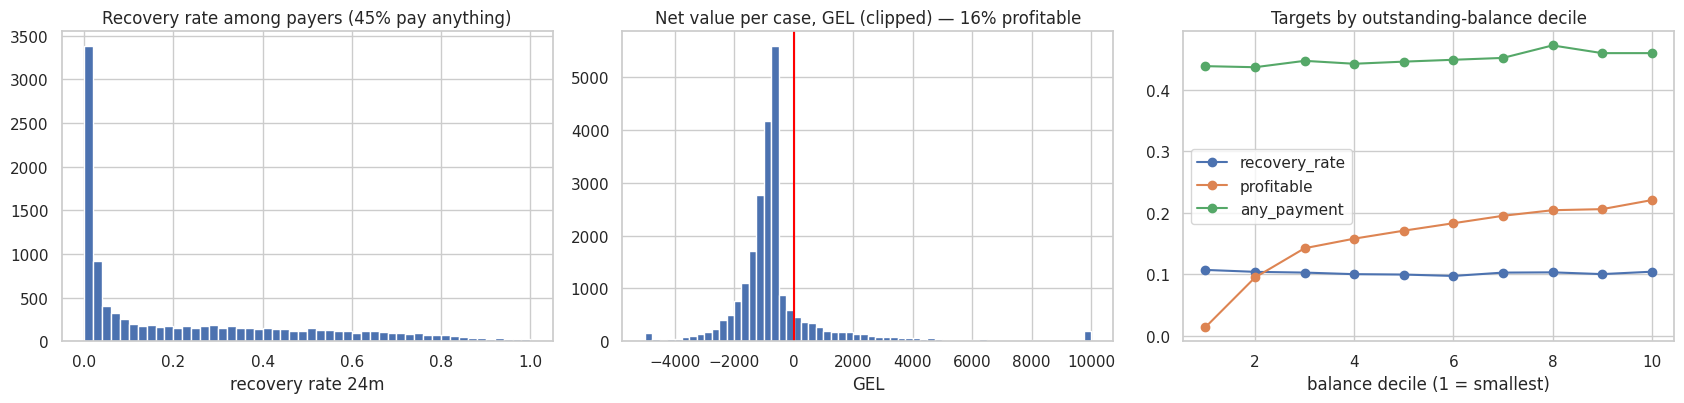

outst,1,2,3,4,5,6,7,8,9,10
recovery_rate,0.107,0.104,0.103,0.100,0.100,0.097,0.103,0.103,0.100,0.104
profitable,0.014,0.095,0.142,0.158,0.171,0.183,0.195,0.204,0.206,0.221
any_payment,0.438,0.436,0.447,0.442,0.445,0.448,0.451,0.472,0.459,0.459


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].hist(cur.loc[cur.any_payment == 1, "recovery_rate_24m"], bins=50)
axes[0].set(title=f"Recovery rate among payers ({cur.any_payment.mean():.0%} pay anything)", xlabel="recovery rate 24m")
axes[1].hist(cur.net_value_24m.clip(-5000, 10000), bins=60)
axes[1].axvline(0, color="red")
axes[1].set(title=f"Net value per case, GEL (clipped) — {cur.profitable.mean():.0%} profitable", xlabel="GEL")

bq = pd.qcut(cur.outst, 10, labels=False) + 1
g = cur.groupby(bq).agg(recovery_rate=("recovery_rate_24m", "mean"), profitable=("profitable", "mean"),
                        any_payment=("any_payment", "mean"))
g.plot(ax=axes[2], marker="o")
axes[2].set(title="Targets by outstanding-balance decile", xlabel="balance decile (1 = smallest)")
plt.tight_layout(); savefig("target_candidates"); plt.show()
display(g.T)

## 7. Time value of money (NPV sensitivity)

In [12]:
month_share = (full[PAY_COLS].sum() / full.paid_total.sum()).values

def npv_recovery(frame, annual_rate):
    disc = (1 + annual_rate) ** (-np.arange(1, HORIZON + 1) / 12)
    observed_npv = frame[PAY_COLS].fillna(0).values @ disc
    fut = {k: (month_share[k:] * disc[k:]).sum() / month_share[k:].sum() if k < HORIZON else 0.0
           for k in range(1, HORIZON + 1)}
    remaining = frame.recovery_24m - frame.paid_total
    return observed_npv + remaining * frame.months_obs.map(fut).values

sens = []
for r in [0.0, 0.08, 0.12, 0.16]:
    npv = npv_recovery(cur, r)
    sens.append({"annual_rate": r, "recovery_npv / nominal": npv.sum() / cur.recovery_24m.sum(),
                 "profitable_share": (npv - cur.court_cost > 0).mean(),
                 "total_net_value_GEL": (npv - cur.court_cost).sum()})
display(pd.DataFrame(sens).set_index("annual_rate"))

df["recovery_npv"] = npv_recovery(df, ANNUAL_DISCOUNT)
df["net_value_npv"] = df.recovery_npv - df.court_cost
cur = df[df.in_scope == 1].copy()

,recovery_npv / nominal,profitable_share,total_net_value_GEL
annual_rate,,,
0.000,1.000,0.159,"-11,171,349.287"
0.080,0.944,0.155,"-12,155,102.550"
0.120,0.919,0.152,"-12,592,450.260"
0.160,0.896,0.150,"-12,998,739.326"


## 8. Time-based splits (in-scope clients)

In [13]:
SPLITS = {"train": ("2023/01", "2024/12"), "valid": ("2025/01", "2025/06"), "test": ("2025/07", "2026/02")}
ROBUST = {"train": ("2023/01", "2024/02"), "test": ("2024/03", "2024/08")}

def assign(period, splits):
    for name, (lo, hi) in splits.items():
        if lo <= period <= hi:
            return name
    return "unused"

df["split"] = df.PERIOD.map(lambda p: assign(p, SPLITS))
df["split_actual_only"] = df.PERIOD.map(lambda p: assign(p, ROBUST))

cur = df[df.in_scope == 1]
summary = cur.groupby("split").agg(
    rows=("CLIENT_KEY", "size"), cohorts=("PERIOD", "nunique"),
    months_observed=("months_obs", lambda s: f"{s.min()}–{s.max()}"),
    projected_share=("label_source", lambda s: (s == "projected").mean()),
    any_payment=("any_payment", "mean"), mean_recovery_rate=("recovery_rate_24m", "mean"),
    profitable=("profitable", "mean"), net_value_total=("net_value_24m", "sum"),
).reindex(["train", "valid", "test"])
display(summary)
display(cur[cur.split_actual_only != "unused"].groupby("split_actual_only")
          .agg(rows=("CLIENT_KEY", "size"), profitable=("profitable", "mean")))

tr = set(cur.loc[cur.split == "train", "CLIENT_KEY"]); te = set(cur.loc[cur.split == "test", "CLIENT_KEY"])
print(f"Clients appearing in both train and test (different court cases): {len(tr & te):,}")

,rows,cohorts,months_observed,projected_share,any_payment,mean_recovery_rate,profitable,net_value_total
split,,,,,,,,
train,12550,24,20–24,0.211,0.453,0.106,0.165,"-5,524,794.155"
valid,4261,6,14–19,1.000,0.461,0.107,0.168,"-1,939,659.265"
test,6359,8,6–13,1.000,0.437,0.092,0.142,"-3,706,895.867"


,rows,profitable
split_actual_only,,
test,3514,0.162
train,6382,0.171


Clients appearing in both train and test (different court cases): 1,445


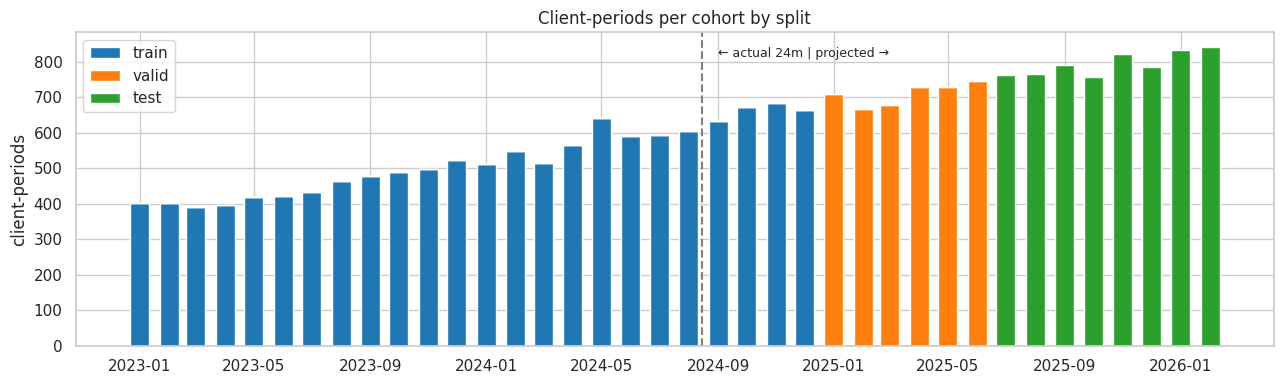

In [14]:
coh = cur.groupby(["PERIOD_DT", "split"]).size().unstack(fill_value=0)[["train", "valid", "test"]]
fig, ax = plt.subplots(figsize=(13, 4))
bottom = np.zeros(len(coh))
for name, color in zip(coh.columns, ["tab:blue", "tab:orange", "tab:green"]):
    ax.bar(coh.index, coh[name], width=20, bottom=bottom, color=color, label=name)
    bottom += coh[name].values
ax.axvline(pd.Timestamp("2024-08-15"), color="grey", ls="--")
ax.text(pd.Timestamp("2024-09-01"), ax.get_ylim()[1] * 0.92, "← actual 24m | projected →", fontsize=9)
ax.set(title="Client-periods per cohort by split", ylabel="client-periods")
ax.legend(); plt.tight_layout(); savefig("splits_timeline"); plt.show()

## 9. Save the modelling dataset and configuration

In [15]:
keep = (["CLIENT_KEY", "PERIOD", "in_scope", "split", "split_actual_only", "label_source", "months_obs",
         "outst", "principal", "n_loans", "court_cost", "paid_total", "dev_factor"]
        + TARGETS + ["recovery_npv", "net_value_npv"]
        + ["has_secured_loans"] + [c for c in FEATURES if c not in ("outst", "n_loans")])
model_df = df[keep]

try:
    out_path = PROC_DIR / "model_dataset.parquet"
    model_df.to_parquet(out_path, index=False)
except ImportError:
    out_path = PROC_DIR / "model_dataset.csv"
    model_df.to_csv(out_path, index=False)

config = {
    "costs": {"fixed_cost": FIXED_COST, "var_cost_rate": VAR_COST_RATE, "fee_basis": FEE_BASIS},
    "horizon_months": HORIZON,
    "annual_discount_rate": ANNUAL_DISCOUNT,
    "development_factors": {int(k): round(float(v), 4) for k, v in dev.items()},
    "splits": SPLITS, "splits_actual_only": ROBUST,
    "targets": {"main": "recovery_rate_24m (two-part: any_payment x rate|payment)",
                "benchmark": "profitable", "evaluation": "net_value_24m (GEL)"},
    "population": "in_scope == 1 (clients with only unsecured loans)",
    "features": [c for c in FEATURES],
    "dropped_features": {"feature_045": "post-enforcement leakage", "feature_050": "constant",
                         "feature_033": "duplicate of feature_017"},
}
with open(CONFIG_DIR / "target_config.json", "w") as f:
    json.dump(config, f, indent=2)

print(f"Saved {model_df.shape[0]:,} rows × {model_df.shape[1]} cols → {out_path.relative_to(PROJECT_DIR)}")
print(f"Saved config → {(CONFIG_DIR / 'target_config.json').relative_to(PROJECT_DIR)}  (safe to commit: no client data)")

Saved 27,029 rows × 70 cols → data/processed/model_dataset.parquet
Saved config → config/target_config.json  (safe to commit: no client data)


## 10. Summary

- **Scope:** clients with only unsecured loans; mixed clients recover far more (likely via collateral) and are excluded, kept for sensitivity.
- **Cost:** 500 GEL once per client-period + 10% of outstanding (per-loan fee kept as a sensitivity).
- **Payment timing:** payers start in month 1; nobody meaningful starts later. Censoring affects *how much*, not *whether*.
- **Censoring:** development factors from fully observed cohorts complete every cohort to 24 months. Backtested:
  unbiased overall and by segment, near-perfect ranking, about 98% label agreement from 6 months.
- **Targets:** model client behaviour (`any_payment`, `recovery_rate_24m`), then apply costs explicitly to get expected net value;
  `profitable` is the benchmark target; all strategies are judged by realised net value in GEL.
- **NPV:** discounting at 12% reduces recovery by under 10%; nominal stays the main target.
- **Splits:** train 2023-01…2024-12, valid 2025-H1, test 2025-07…2026-02, plus an actual-outcomes-only robustness split.